# ViT Traffic Sign (GTSRB): shared inference + verification
Model:   kelvinandreas/vit-traffic-sign-GTSRB
Dataset: tanganke/gtsrb  (splits: test, motion_blur, gaussian_noise)


In [1]:
# Config
import os, sys, json, time, platform
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from datasets import load_dataset
from transformers import ViTForImageClassification, ViTImageProcessor
import transformers, datasets

MODEL_PATH = r"C:\Users\rudra\AIV UE\results\vit_model"
DATA_DIR = r"C:\Users\rudra\AIV UE\results\data"
MODEL = "kelvinandreas/vit-traffic-sign-GTSRB"
DATA = "tanganke/gtsrb"
SPLITS = ["test", "motion_blur", "gaussian_noise"]   # add more corruptions later if time permits
BATCH_SIZE = 64        # lower to 16 if you run out of memory
LIMIT = None           # e.g. 256 for a quick test; None = full splits
OUT_DIR = "results"
SEED = 0

# If the label check below shows that the model's class order differs from the dataset's,
MODEL_TO_DATASET = None

os.makedirs(OUT_DIR, exist_ok=True)

if torch.cuda.is_available():
    device = "cuda"
elif getattr(torch.backends, "mps", None) and torch.backends.mps.is_available():
    device = "mps"
else:
    device = "cpu"
print("device:", device)

W1107 18:26:09.201000 13988 site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


device: cpu


In [2]:
# Load model + image processor
processor = ViTImageProcessor.from_pretrained(MODEL_PATH)
model = ViTForImageClassification.from_pretrained(MODEL_PATH).to(device).eval()

print(processor)
print("num_labels:", model.config.num_labels)
assert model.config.num_labels == 43, "Expected 43 classes"

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

ViTImageProcessor {
  "do_normalize": true,
  "do_rescale": true,
  "do_resize": true,
  "image_mean": [
    0.5,
    0.5,
    0.5
  ],
  "image_processor_type": "ViTImageProcessor",
  "image_std": [
    0.5,
    0.5,
    0.5
  ],
  "resample": 2,
  "rescale_factor": 0.00392156862745098,
  "size": {
    "height": 224,
    "width": 224
  }
}

num_labels: 43


In [3]:
# Load clean test split (used for label checks)
ds_test = load_dataset(DATA_DIR, split="test")
print(ds_test)
ds_names = ds_test.features["label"].names
assert len(ds_names) == 43, "Expected 43 dataset classes"
print("columns:", ds_test.column_names)

Dataset({
    features: ['image', 'label'],
    num_rows: 12630
})
columns: ['image', 'label']


In [4]:
# Check 1: label names, dataset vs model (compare by eye)
id2label = model.config.id2label
print(f"{'id':>2} | {'dataset name':<55} | model name")
for i in range(43):
    print(f"{i:>2} | {ds_names[i][:55]:<55} | {id2label[i]}")
# If the model names are generic (e.g. LABEL_0) you cannot compare names; rely on Check 2.

id | dataset name                                            | model name
 0 | red and white circle 20 kph speed limit                 | Speed limit (20km/h)
 1 | red and white circle 30 kph speed limit                 | Speed limit (30km/h)
 2 | red and white circle 50 kph speed limit                 | Speed limit (50km/h)
 3 | red and white circle 60 kph speed limit                 | Speed limit (60km/h)
 4 | red and white circle 70 kph speed limit                 | Speed limit (70km/h)
 5 | red and white circle 80 kph speed limit                 | Speed limit (80km/h)
 6 | end / de-restriction of 80 kph speed limit              | End of speed limit (80km/h)
 7 | red and white circle 100 kph speed limit                | Speed limit (100km/h)
 8 | red and white circle 120 kph speed limit                | Speed limit (120km/h)
 9 | red and white circle red car and black car no passing   | No passing
10 | red and white circle red truck and black car no passing | No passing veh over 3.5 

In [5]:
# Helper: raw model prediction for a list of PIL images
@torch.inference_mode()
def model_probs(images):
    imgs = [im.convert("RGB") for im in images]
    inputs = processor(images=imgs, return_tensors="pt").to(device)
    return model(**inputs).logits.softmax(-1).cpu()

def to_dataset_order(probs):
    """Reorder the columns of probs into dataset class order if a mapping is set."""
    if MODEL_TO_DATASET is None:
        return probs
    m = torch.as_tensor(MODEL_TO_DATASET)
    out = torch.zeros_like(probs)
    out[:, m] = probs            # column j (model class) -> column m[j] (dataset class)
    return out

In [6]:
# Check 2: accuracy on a RANDOM sample of the clean test set (test is sorted by class)
sample = ds_test.shuffle(seed=SEED).select(range(500))
p = to_dataset_order(model_probs(sample["image"]))
pred = p.argmax(-1).numpy()
true = np.array(sample["label"])
acc = (pred == true).mean()
print(f"sample accuracy (500 random test images): {acc:.3f}")

if acc < 0.8:
    # Diagnose: which model class does each dataset class map to most often?
    raw = model_probs(sample["image"]).argmax(-1).numpy()
    suggestion = {}
    for c in range(43):
        mask = true == c
        if mask.any():
            vals, counts = np.unique(raw[mask], return_counts=True)
            suggestion[c] = (int(vals[counts.argmax()]), int(counts.max()), int(mask.sum()))
    print("dataset class -> most frequent model class (votes, samples):")
    for c, v in suggestion.items():
        print(f"  {c:>2} -> {v[0]:>2}  ({v[1]}/{v[2]})")
    raise RuntimeError(
        "Accuracy is far below the ~98% reported on the model card. Either the label order "
        "differs (inspect the table above, then set MODEL_TO_DATASET) or preprocessing is wrong. "
        "Do NOT continue until this is explained.")

sample accuracy (500 random test images): 0.942


In [7]:
import time
from tqdm import tqdm

def predict_split(split_name, limit=None, bs=BATCH_SIZE):
    if split_name == "test":
        data = ds_test
    else:
        path = os.path.join(DATA_DIR, f"{split_name}-00000-of-00001.parquet")
        assert os.path.exists(path), f"missing file: {path}"
        data = load_dataset("parquet", data_files=path, split="train")
    if limit:
        data = data.select(range(limit))
    rows, t0 = [], time.time()
    n_batches = (len(data) + bs - 1) // bs
    for b, start in enumerate(range(0, len(data), bs), 1):
        batch = data[start:start + bs]
        probs = to_dataset_order(model_probs(batch["image"]))
        conf, pred = probs.max(-1)
        for i in range(len(pred)):
            y = int(batch["label"][i])
            rows.append({
                "split": split_name,
                "image_id": start + i,
                "true_label": y,
                "predicted_label": int(pred[i]),
                "confidence": float(conf[i]),
                "correct": int(pred[i]) == y,
                "class_scores": probs[i].tolist(),
            })
        if b <= 3 or b % 10 == 0:
            el = time.time() - t0
            print(f"{split_name}: batch {b}/{n_batches} | {el:.0f}s elapsed | "
                  f"ETA {el / b * (n_batches - b) / 60:.1f} min", flush=True)
    return pd.DataFrame(rows)

In [8]:
# Run all splits (each split is saved separately, so a crash does not lose everything)
suffix = f"_limit{LIMIT}" if LIMIT else ""
frames = []
for s in SPLITS:
    path = os.path.join(OUT_DIR, f"pred_{s}{suffix}.parquet")
    if os.path.exists(path):
        print(f"{s}: loading existing {path}")
        frames.append(pd.read_parquet(path))
        continue
    t0 = time.time()
    df_s = predict_split(s, limit=LIMIT)
    df_s.to_parquet(path)
    print(f"{s}: {len(df_s)} rows in {time.time() - t0:.0f}s -> {path}")
    frames.append(df_s)

preds = pd.concat(frames, ignore_index=True)
final_name = "predictions.parquet" if not LIMIT else "predictions_sample.parquet"
preds.to_parquet(os.path.join(OUT_DIR, final_name))
print("saved", final_name, preds.shape)

test: loading existing results\pred_test.parquet
motion_blur: batch 1/198 | 14s elapsed | ETA 44.3 min
motion_blur: batch 2/198 | 27s elapsed | ETA 44.1 min
motion_blur: batch 3/198 | 40s elapsed | ETA 43.8 min
motion_blur: batch 10/198 | 135s elapsed | ETA 42.2 min
motion_blur: batch 20/198 | 273s elapsed | ETA 40.5 min
motion_blur: batch 30/198 | 407s elapsed | ETA 37.9 min
motion_blur: batch 40/198 | 540s elapsed | ETA 35.6 min
motion_blur: batch 50/198 | 673s elapsed | ETA 33.2 min
motion_blur: batch 60/198 | 806s elapsed | ETA 30.9 min
motion_blur: batch 70/198 | 942s elapsed | ETA 28.7 min
motion_blur: batch 80/198 | 1077s elapsed | ETA 26.5 min
motion_blur: batch 90/198 | 1210s elapsed | ETA 24.2 min
motion_blur: batch 100/198 | 1343s elapsed | ETA 21.9 min
motion_blur: batch 110/198 | 1478s elapsed | ETA 19.7 min
motion_blur: batch 120/198 | 1611s elapsed | ETA 17.4 min
motion_blur: batch 130/198 | 1744s elapsed | ETA 15.2 min
motion_blur: batch 140/198 | 1878s elapsed | ETA 13

Generating train split: 0 examples [00:00, ? examples/s]

gaussian_noise: batch 1/198 | 13s elapsed | ETA 43.9 min
gaussian_noise: batch 2/198 | 27s elapsed | ETA 43.5 min
gaussian_noise: batch 3/198 | 40s elapsed | ETA 43.2 min
gaussian_noise: batch 10/198 | 133s elapsed | ETA 41.6 min
gaussian_noise: batch 20/198 | 265s elapsed | ETA 39.3 min
gaussian_noise: batch 30/198 | 398s elapsed | ETA 37.2 min
gaussian_noise: batch 40/198 | 533s elapsed | ETA 35.1 min
gaussian_noise: batch 50/198 | 669s elapsed | ETA 33.0 min
gaussian_noise: batch 60/198 | 804s elapsed | ETA 30.8 min
gaussian_noise: batch 70/198 | 943s elapsed | ETA 28.7 min
gaussian_noise: batch 80/198 | 1080s elapsed | ETA 26.6 min
gaussian_noise: batch 90/198 | 1214s elapsed | ETA 24.3 min
gaussian_noise: batch 100/198 | 1350s elapsed | ETA 22.0 min
gaussian_noise: batch 110/198 | 1482s elapsed | ETA 19.8 min
gaussian_noise: batch 120/198 | 1615s elapsed | ETA 17.5 min
gaussian_noise: batch 130/198 | 1748s elapsed | ETA 15.2 min
gaussian_noise: batch 140/198 | 1880s elapsed | ETA 

In [9]:
# Check 3: automatic verification
print("\n== Verification ==")
print(preds.groupby("split").agg(n=("correct", "size"), accuracy=("correct", "mean"),
                                 mean_conf=("confidence", "mean")))

expected_n = LIMIT if LIMIT else 12630
for s in SPLITS:
    n = (preds.split == s).sum()
    print(f"[{'OK' if n == expected_n else 'CHECK'}] {s}: {n} rows (expected {expected_n})")

# labels must line up index by index across splits so image_id means the same image
ref = preds[preds.split == SPLITS[0]].sort_values("image_id").true_label.values
for s in SPLITS[1:]:
    cur = preds[preds.split == s].sort_values("image_id").true_label.values
    print(f"[{'OK' if len(cur) == len(ref) and (cur == ref).all() else 'MISMATCH'}] "
          f"true_label aligned: {SPLITS[0]} vs {s}")

scores = np.array(preds.class_scores.tolist())
print("[OK]" if scores.shape[1] == 43 else "[CHECK]", "class_scores width:", scores.shape[1])
print("[OK]" if np.allclose(scores.sum(1), 1, atol=1e-3) else "[CHECK]", "scores sum to 1")
print("[OK]" if np.allclose(scores.max(1), preds.confidence.values, atol=1e-5) else "[CHECK]",
      "confidence == max score")
print("[OK]" if (preds.predicted_label.values == scores.argmax(1)).all() else "[CHECK]",
      "predicted_label == argmax(scores)")

acc_by_split = preds.groupby("split").correct.mean()
if acc_by_split.get("test", 0) < acc_by_split.drop("test", errors="ignore").max():
    print("[CHECK] a corrupted split scores higher than clean; investigate before analysis")


== Verification ==
                    n  accuracy  mean_conf
split                                     
gaussian_noise  12630  0.850040   0.942630
motion_blur     12630  0.926841   0.966009
test            12630  0.953761   0.977601
[OK] test: 12630 rows (expected 12630)
[OK] motion_blur: 12630 rows (expected 12630)
[OK] gaussian_noise: 12630 rows (expected 12630)
[OK] true_label aligned: test vs motion_blur
[OK] true_label aligned: test vs gaussian_noise
[OK] class_scores width: 43
[OK] scores sum to 1
[OK] confidence == max score
[OK] predicted_label == argmax(scores)


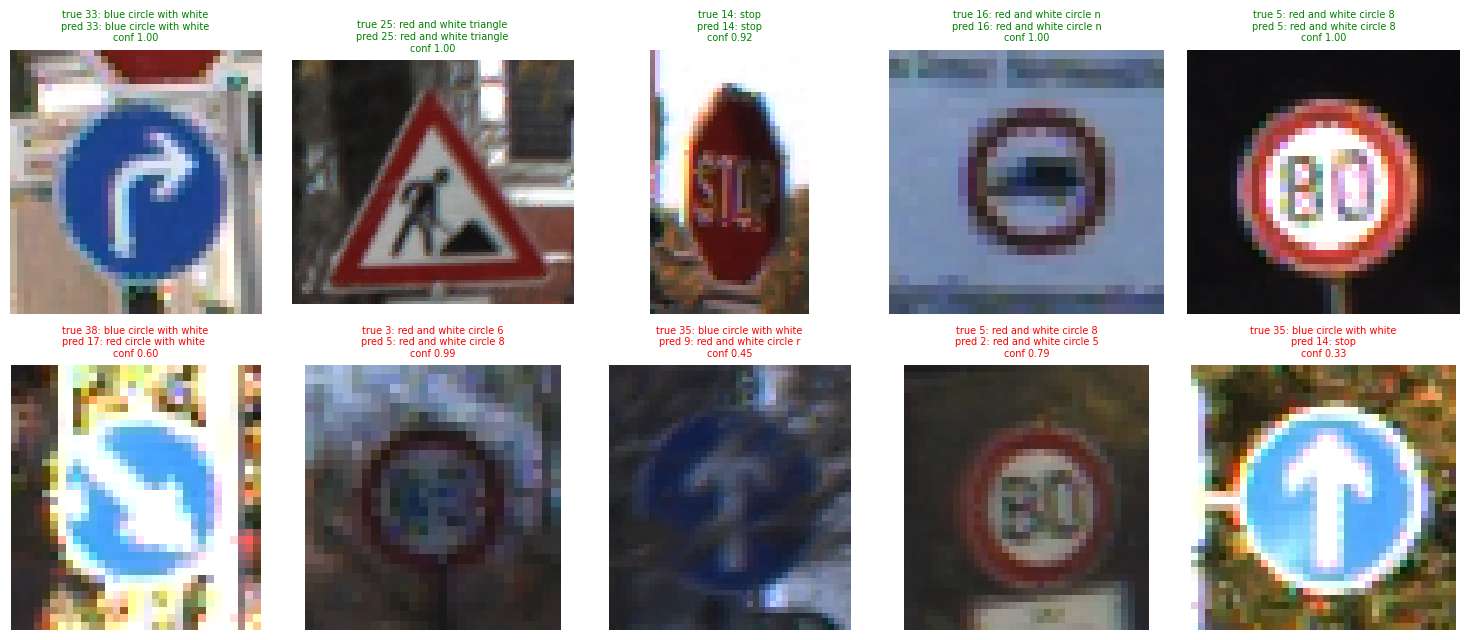

In [10]:
# Check 4: look at images (true vs predicted), including some errors
test_preds = preds[preds.split == "test"].set_index("image_id")
rng = np.random.default_rng(SEED)
wrong = test_preds[~test_preds.correct].index.values
right = test_preds[test_preds.correct].index.values
pick = list(rng.choice(right, size=min(5, len(right)), replace=False)) + \
       list(rng.choice(wrong, size=min(5, len(wrong)), replace=False)) if len(wrong) else \
       list(rng.choice(right, size=min(10, len(right)), replace=False))

fig, axes = plt.subplots(2, 5, figsize=(15, 6.5))
for ax, i in zip(axes.flat, pick):
    r = test_preds.loc[i]
    ax.imshow(ds_test[int(i)]["image"]); ax.axis("off")
    ax.set_title(f"true {int(r.true_label)}: {ds_names[int(r.true_label)][:22]}\n"
                 f"pred {int(r.predicted_label)}: {ds_names[int(r.predicted_label)][:22]}\n"
                 f"conf {r.confidence:.2f}", fontsize=7,
                 color="green" if r.correct else "red")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "spot_check.png"), dpi=120)
plt.show()

In [11]:
# Record versions (copy into README)
def hub_sha(repo, repo_type):
    try:
        from huggingface_hub import HfApi
        return HfApi().repo_info(repo, repo_type=repo_type).sha
    except Exception as e:
        return f"unavailable ({type(e).__name__})"

env = {
    "date": time.strftime("%Y-%m-%d %H:%M"),
    "python": platform.python_version(),
    "torch": torch.__version__,
    "transformers": transformers.__version__,
    "datasets": datasets.__version__,
    "device": device,
    "model": MODEL, "model_commit": hub_sha(MODEL, "model"),
    "dataset": DATA, "dataset_commit": hub_sha(DATA, "dataset"),
    "splits": SPLITS, "limit": LIMIT, "label_mapping": MODEL_TO_DATASET,
    "class_scores": "softmax probabilities in dataset class order",
}
with open(os.path.join(OUT_DIR, "environment.json"), "w") as f:
    json.dump(env, f, indent=2)
print(json.dumps(env, indent=2))

{
  "date": "2026-11-07 19:56",
  "python": "3.11.14",
  "torch": "2.9.1+cpu",
  "transformers": "5.22.1",
  "datasets": "5.1.0",
  "device": "cpu",
  "model": "kelvinandreas/vit-traffic-sign-GTSRB",
  "model_commit": "unavailable (ConnectError)",
  "dataset": "tanganke/gtsrb",
  "dataset_commit": "unavailable (ConnectError)",
  "splits": [
    "test",
    "motion_blur",
    "gaussian_noise"
  ],
  "limit": null,
  "label_mapping": null,
  "class_scores": "softmax probabilities in dataset class order"
}


In [13]:
import json; json.dump(ds_names, open("results/class_names.json", "w"))